# Minería de Datos
## Análisis de factores asociados al bajo rendimiento académico

**Pregunta de negocio:** ¿Qué factores académicos, familiares y de comportamiento se asocian con el bajo rendimiento académico y pueden ayudar a identificar estudiantes que requieren seguimiento?

**Alcance de esta versión:** el repositorio UCI ofrece archivos separados para Matemáticas y Portugués. En este notebook se analiza únicamente el archivo de Matemáticas. Como no hay un identificador individual común documentado que permita confirmar que una fila de un archivo es la misma persona que una fila del otro, no se construye una llave artificial ni se cruzan perfiles. De esta manera se conserva la muestra original de Matemáticas.

**Definición operativa:** para este ejercicio se considera bajo rendimiento una calificación final `G3 < 10` en una escala de 0 a 20. Es un criterio de trabajo para el análisis y debe confirmarse con el criterio académico del curso o institución.





## Preparación y carga de datos

Sube `student-mat.csv` cuando Colab abra el selector de archivos. También se acepta un nombre descargado como `student-mat(4).csv`. No es necesario subir ni combinar `student-por.csv` para este análisis.

In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Puedes subir student-mat.csv o un nombre como student-mat(4).csv.
uploaded = files.upload()

candidatos_mat = [
    nombre for nombre in uploaded.keys()
    if nombre.lower().startswith("student-mat") and nombre.lower().endswith(".csv")
]

if not candidatos_mat:
    raise FileNotFoundError(
        "Debes subir el archivo student-mat.csv (también se acepta student-mat(4).csv)."
    )

# Si hay un archivo con el nombre exacto, se prefiere.
archivo_mat = next(
    (nombre for nombre in candidatos_mat if nombre.lower() == "student-mat.csv"),
    candidatos_mat[0]
)

mat = pd.read_csv(archivo_mat, sep=";")

# Se agrega el sufijo _mat para identificar claramente el origen de las columnas.
datos = mat.add_suffix("_mat").copy()

print("Archivo utilizado:", archivo_mat)
print("Dimensiones originales de Matemáticas:", mat.shape)
print("Dimensiones de la base de trabajo:", datos.shape)
display(datos.head())

Saving student-mat.csv to student-mat.csv
Saving student-por.csv to student-por.csv
Archivo utilizado: student-mat.csv
Dimensiones originales de Matemáticas: (395, 33)
Dimensiones de la base de trabajo: (395, 33)


,school_mat,sex_mat,age_mat,address_mat,famsize_mat,Pstatus_mat,Medu_mat,Fedu_mat,Mjob_mat,Fjob_mat,...,famrel_mat,freetime_mat,goout_mat,Dalc_mat,Walc_mat,health_mat,absences_mat,G1_mat,G2_mat,G3_mat
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


Calidad de datos

Se revisan tipos de datos, valores faltantes, registros duplicados, rangos válidos y valores atípicos. Las variables numéricas se convierten explícitamente a formato numérico cuando corresponde. No se eliminan registros automáticamente: cada decisión se justifica con base en la documentación y la revisión de los casos.


In [2]:
# Variables numéricas del conjunto de Matemáticas
variables_numericas = [
    "age_mat", "Medu_mat", "Fedu_mat", "traveltime_mat",
    "studytime_mat", "failures_mat", "famrel_mat", "freetime_mat",
    "goout_mat", "Dalc_mat", "Walc_mat", "health_mat",
    "absences_mat", "G1_mat", "G2_mat", "G3_mat"
]

columnas_convertidas = []
for columna in variables_numericas:
    tipo_anterior = datos[columna].dtype
    datos[columna] = pd.to_numeric(datos[columna], errors="coerce")
    tipo_actual = datos[columna].dtype
    if tipo_actual != tipo_anterior:
        columnas_convertidas.append((columna, str(tipo_anterior), str(tipo_actual)))

print("Columnas cuyo tipo cambió:")
if columnas_convertidas:
    display(pd.DataFrame(
        columnas_convertidas,
        columns=["Columna", "Tipo anterior", "Tipo actual"]
    ))
else:
    print("No fue necesario cambiar tipos: las variables numéricas ya estaban en formato numérico.")

print("\nINFORMACIÓN GENERAL")
datos.info()

print("\nTIPOS DE DATOS")
display(datos.dtypes.to_frame("tipo"))

print("\nVALORES NULOS POR COLUMNA")
display(datos.isnull().sum().to_frame("valores_nulos"))
print("Total de valores nulos:", int(datos.isnull().sum().sum()))

print("\nREGISTROS DUPLICADOS COMPLETOS:", int(datos.duplicated().sum()))

print("\nESTADÍSTICAS DESCRIPTIVAS")
display(datos[variables_numericas].describe())

Columnas cuyo tipo cambió:
No fue necesario cambiar tipos: las variables numéricas ya estaban en formato numérico.

INFORMACIÓN GENERAL
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   school_mat      395 non-null    object
 1   sex_mat         395 non-null    object
 2   age_mat         395 non-null    int64 
 3   address_mat     395 non-null    object
 4   famsize_mat     395 non-null    object
 5   Pstatus_mat     395 non-null    object
 6   Medu_mat        395 non-null    int64 
 7   Fedu_mat        395 non-null    int64 
 8   Mjob_mat        395 non-null    object
 9   Fjob_mat        395 non-null    object
 10  reason_mat      395 non-null    object
 11  guardian_mat    395 non-null    object
 12  traveltime_mat  395 non-null    int64 
 13  studytime_mat   395 non-null    int64 
 14  failures_mat    395 non-null    int64 
 15  school

,tipo
school_mat,object
sex_mat,object
age_mat,int64
address_mat,object
famsize_mat,object
Pstatus_mat,object
Medu_mat,int64
Fedu_mat,int64
Mjob_mat,object
Fjob_mat,object



VALORES NULOS POR COLUMNA


,valores_nulos
school_mat,0
sex_mat,0
age_mat,0
address_mat,0
famsize_mat,0
Pstatus_mat,0
Medu_mat,0
Fedu_mat,0
Mjob_mat,0
Fjob_mat,0


Total de valores nulos: 0

REGISTROS DUPLICADOS COMPLETOS: 0

ESTADÍSTICAS DESCRIPTIVAS


,age_mat,Medu_mat,Fedu_mat,traveltime_mat,studytime_mat,failures_mat,famrel_mat,freetime_mat,goout_mat,Dalc_mat,Walc_mat,health_mat,absences_mat,G1_mat,G2_mat,G3_mat
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


### Validación de rangos y consistencias

La documentación del conjunto describe las notas `G1`, `G2` y `G3` en el intervalo de 0 a 20, y las ausencias en el intervalo de 0 a 93. Se comprueban esos rangos antes de decidir si hay errores. Los registros fuera de rango se deben revisar; este notebook no los corrige ni elimina sin inspección.

In [3]:
# Revisar notas fuera del rango documentado (0 a 20)
columnas_notas = ["G1_mat", "G2_mat", "G3_mat"]
mascara_notas_invalidas = datos[columnas_notas].lt(0).any(axis=1) | datos[columnas_notas].gt(20).any(axis=1)
notas_fuera_rango = datos.loc[mascara_notas_invalidas, columnas_notas]

# Revisar ausencias fuera del rango documentado (0 a 93)
mascara_ausencias_invalidas = (datos["absences_mat"] < 0) | (datos["absences_mat"] > 93)
ausencias_fuera_rango = datos.loc[mascara_ausencias_invalidas, ["absences_mat"]]

print("Registros con alguna nota fuera de 0–20:", len(notas_fuera_rango))
display(notas_fuera_rango)
print("Registros con ausencias fuera de 0–93:", len(ausencias_fuera_rango))
display(ausencias_fuera_rango)

print("\nDecisión: si estas tablas están vacías, no se detectaron valores fuera de los rangos documentados. Si aparece algún registro, se revisa contra la fuente antes de corregirlo o excluirlo.")

Registros con alguna nota fuera de 0–20: 0


,G1_mat,G2_mat,G3_mat


Registros con ausencias fuera de 0–93: 0


,absences_mat



Decisión: si estas tablas están vacías, no se detectaron valores fuera de los rangos documentados. Si aparece algún registro, se revisa contra la fuente antes de corregirlo o excluirlo.


### Identificación y tratamiento de valores atípicos

Se utiliza el rango intercuartílico (IQR) para identificar observaciones extremas. Un valor atípico estadístico no es necesariamente un error, por lo que no se eliminan registros automáticamente.

**Resultado calculado para los 395 registros de Matemáticas:**

- **Ausencias (`absences_mat`):** el IQR identifica 15 observaciones por encima del límite superior de 20 (entre 21 y 75 ausencias). Están dentro del rango documentado de 0 a 93; se conservan y se marcan en `marca_atipico_ausencias`, porque pueden representar ausencias reales.
- **Calificación final (`G3_mat`):** el IQR no identifica observaciones atípicas (0 casos). Los límites IQR son -1 y 23 y todas las notas están dentro del rango válido de 0 a 20. No se modifica ni elimina ningún registro de esta variable.

La celda siguiente recalcula los límites y crea las marcas. Si se cambia el archivo de entrada, deben utilizarse los nuevos valores que aparezcan en la ejecución.


In [4]:
def detectar_atipicos(data, columna):
    q1 = data[columna].quantile(0.25)
    q3 = data[columna].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    mascara = (data[columna] < limite_inferior) | (data[columna] > limite_superior)
    atipicos = data.loc[mascara, [columna]].copy()
    atipicos.insert(0, "indice_original", atipicos.index)

    print(f"\nVariable: {columna}")
    print(f"Q1: {q1:.2f} | Q3: {q3:.2f} | IQR: {iqr:.2f}")
    print(f"Límite inferior: {limite_inferior:.2f}")
    print(f"Límite superior: {limite_superior:.2f}")
    print(f"Cantidad de valores atípicos: {len(atipicos)}")
    display(atipicos)
    return atipicos

atipicos_ausencias = detectar_atipicos(datos, "absences_mat")
atipicos_calificaciones = detectar_atipicos(datos, "G3_mat")

# Se marcan en la base sin borrar ni modificar el valor original.
datos["marca_atipico_ausencias"] = datos.index.isin(atipicos_ausencias["indice_original"])
datos["marca_atipico_G3"] = datos.index.isin(atipicos_calificaciones["indice_original"])

print("\nRegistros marcados por ausencias:", int(datos["marca_atipico_ausencias"].sum()))
print("Registros marcados por G3:", int(datos["marca_atipico_G3"].sum()))


Variable: absences_mat
Q1: 0.00 | Q3: 8.00 | IQR: 8.00
Límite inferior: -12.00
Límite superior: 20.00
Cantidad de valores atípicos: 15


,indice_original,absences_mat
40,40,25
74,74,54
103,103,26
183,183,56
198,198,24
205,205,28
216,216,22
260,260,21
276,276,75
277,277,22



Variable: G3_mat
Q1: 8.00 | Q3: 14.00 | IQR: 6.00
Límite inferior: -1.00
Límite superior: 23.00
Cantidad de valores atípicos: 0


,indice_original,G3_mat



Registros marcados por ausencias: 15
Registros marcados por G3: 0


## 2. Análisis exploratorio de datos (EDA)

La variable `G3_mat` representa la calificación final. Para este ejercicio se define de manera operativa el bajo rendimiento como `G3_mat < 10` en la escala de 0 a 20. Los resultados son descriptivos y no demuestran causalidad.

Se presentan estadísticas descriptivas, frecuencias, tres gráficos y cinco hallazgos conectados con la identificación de estudiantes que podrían requerir seguimiento.


In [5]:
UMBRAL_BAJO_RENDIMIENTO = 10

# Variable objetivo descriptiva: 1 = bajo rendimiento; 0 = G3 >= 10
y = (datos["G3_mat"] < UMBRAL_BAJO_RENDIMIENTO).astype(int)

print("ESTADÍSTICAS DESCRIPTIVAS DE VARIABLES PRINCIPALES")
display(datos[["G3_mat", "absences_mat", "studytime_mat", "failures_mat", "G1_mat", "G2_mat"]].describe())

print("\nFRECUENCIA DE CALIFICACIONES FINALES")
display(datos["G3_mat"].value_counts().sort_index())

print("\nFRECUENCIA DE TIEMPO DE ESTUDIO")
display(datos["studytime_mat"].value_counts().sort_index())

print("\nFRECUENCIA DE REPROBACIONES PREVIAS")
display(datos["failures_mat"].value_counts().sort_index())

print("\nDISTRIBUCIÓN DEL BAJO RENDIMIENTO (1 = G3 < 10; 0 = G3 >= 10)")
display(y.value_counts().rename(index={0: "Aprobación", 1: "Bajo rendimiento"}))
display((y.value_counts(normalize=True) * 100).round(2).rename(index={0: "Aprobación (%)", 1: "Bajo rendimiento (%)"}))

ESTADÍSTICAS DESCRIPTIVAS DE VARIABLES PRINCIPALES


,G3_mat,absences_mat,studytime_mat,failures_mat,G1_mat,G2_mat
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,10.415190,5.708861,2.035443,0.334177,10.908861,10.713924
std,4.581443,8.003096,0.839240,0.743651,3.319195,3.761505
min,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,8.000000,0.000000,1.000000,0.000000,8.000000,9.000000
50%,11.000000,4.000000,2.000000,0.000000,11.000000,11.000000
75%,14.000000,8.000000,2.000000,0.000000,13.000000,13.000000
max,20.000000,75.000000,4.000000,3.000000,19.000000,19.000000



FRECUENCIA DE CALIFICACIONES FINALES


,count
G3_mat,
0,38
4,1
5,7
6,15
7,9
8,32
9,28
10,56
11,47



FRECUENCIA DE TIEMPO DE ESTUDIO


,count
studytime_mat,
1,105
2,198
3,65
4,27



FRECUENCIA DE REPROBACIONES PREVIAS


,count
failures_mat,
0,312
1,50
2,17
3,16



DISTRIBUCIÓN DEL BAJO RENDIMIENTO (1 = G3 < 10; 0 = G3 >= 10)


,count
G3_mat,
Aprobación,265
Bajo rendimiento,130


,proportion
G3_mat,
Aprobación (%),67.09
Bajo rendimiento (%),32.91


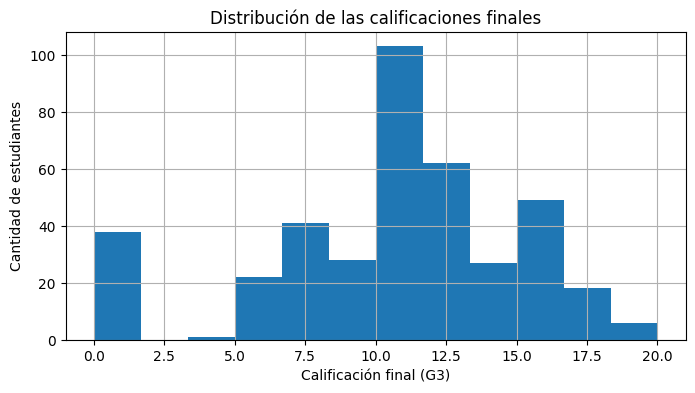

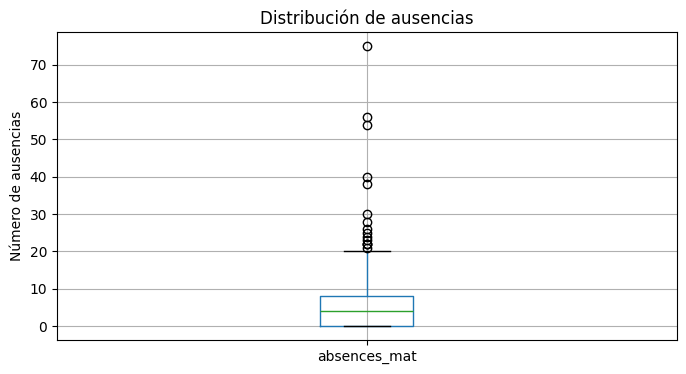

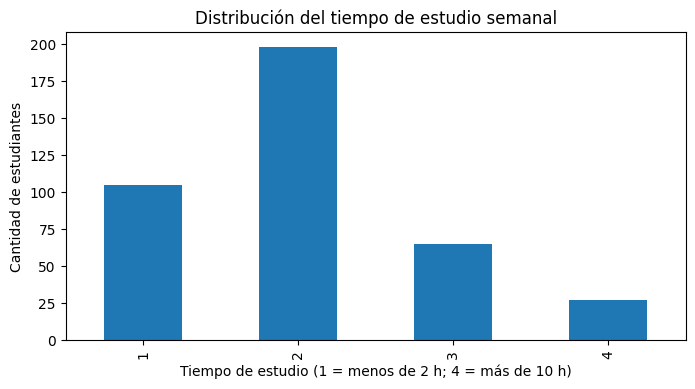

In [6]:
# Gráfica 1: distribución de calificaciones finales
plt.figure(figsize=(8, 4))
datos["G3_mat"].hist(bins=12)
plt.title("Distribución de las calificaciones finales")
plt.xlabel("Calificación final (G3)")
plt.ylabel("Cantidad de estudiantes")
plt.show()

# Gráfica 2: valores atípicos de ausencias
plt.figure(figsize=(8, 4))
datos.boxplot(column="absences_mat")
plt.title("Distribución de ausencias")
plt.ylabel("Número de ausencias")
plt.show()

# Gráfica 3: frecuencia del tiempo de estudio
plt.figure(figsize=(8, 4))
datos["studytime_mat"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribución del tiempo de estudio semanal")
plt.xlabel("Tiempo de estudio (1 = menos de 2 h; 4 = más de 10 h)")
plt.ylabel("Cantidad de estudiantes")
plt.show()

### Hallazgos del análisis exploratorio

La siguiente celda genera cinco hallazgos con cifras calculadas desde la muestra completa de Matemáticas. Al interpretar, conserva las cifras que aparezcan después de ejecutar el notebook. Las diferencias son descriptivas y no demuestran causalidad.

In [7]:
# Hallazgo 1: rendimiento general y proporción de bajo rendimiento
promedio_g3 = datos["G3_mat"].mean()
mediana_g3 = datos["G3_mat"].median()
porcentaje_bajo = y.mean() * 100
print(
    f"1. Rendimiento general: la media de G3 es {promedio_g3:.2f}/20 y "
    f"la mediana es {mediana_g3:.2f}/20. El {porcentaje_bajo:.1f}% de los "
    "estudiantes presenta bajo rendimiento (G3 < 10). Esto permite dimensionar "
    "la proporción que podría requerir seguimiento."
)

# Hallazgo 2: tiempo de estudio
promedios_estudio = datos.groupby("studytime_mat")["G3_mat"].mean().sort_index()
conteos_estudio = datos["studytime_mat"].value_counts().sort_index()
if len(promedios_estudio) >= 2:
    nivel_mayor = int(promedios_estudio.idxmax())
    nivel_menor = int(promedios_estudio.idxmin())
    print(
        f"2. Tiempo de estudio: el promedio más alto de G3 aparece en la categoría "
        f"{nivel_mayor} ({promedios_estudio.max():.2f}; n={conteos_estudio[nivel_mayor]}), "
        f"y el más bajo en la categoría {nivel_menor} ({promedios_estudio.min():.2f}; "
        f"n={conteos_estudio[nivel_menor]}). La diferencia sugiere una asociación "
        "que merece seguimiento, pero no prueba que estudiar más cause una nota mayor."
    )

# Hallazgo 3: reprobaciones previas
sin_reprobaciones = datos.loc[datos["failures_mat"] == 0, "G3_mat"]
con_reprobaciones = datos.loc[datos["failures_mat"] > 0, "G3_mat"]
if len(sin_reprobaciones) and len(con_reprobaciones):
    print(
        f"3. Reprobaciones previas: el promedio de G3 es {sin_reprobaciones.mean():.2f} "
        f"sin reprobaciones previas (n={len(sin_reprobaciones)}) y "
        f"{con_reprobaciones.mean():.2f} con al menos una reprobación (n={len(con_reprobaciones)}). "
        "El antecedente de reprobación puede ser una señal útil para priorizar acompañamiento."
    )

# Hallazgo 4: ausencias y calificación final
correlacion_ausencias = datos["absences_mat"].corr(datos["G3_mat"])
print(
    f"4. Ausencias y calificación: la correlación de Pearson entre ausencias y G3 es "
    f"{correlacion_ausencias:.3f}. Este valor describe la intensidad y dirección de la "
    "asociación lineal en la muestra; por sí solo no permite concluir causalidad."
)

# Hallazgo 5: apoyo escolar extra
if "schoolsup_mat" in datos.columns:
    tabla_apoyo = datos.assign(bajo_rendimiento=y).groupby("schoolsup_mat").agg(
        estudiantes=("G3_mat", "size"),
        promedio_G3=("G3_mat", "mean"),
        porcentaje_bajo=("bajo_rendimiento", lambda s: s.mean() * 100)
    )
    print("5. Apoyo escolar adicional: promedio final y porcentaje de bajo rendimiento por grupo (yes/no).")
    display(tabla_apoyo.round(2))
    print("La tabla permite comparar descriptivamente los grupos; el apoyo no debe interpretarse como causa del resultado, porque puede ofrecerse precisamente a estudiantes que ya presentan dificultades.")

1. Rendimiento general: la media de G3 es 10.42/20 y la mediana es 11.00/20. El 32.9% de los estudiantes presenta bajo rendimiento (G3 < 10). Esto permite dimensionar la proporción que podría requerir seguimiento.
2. Tiempo de estudio: el promedio más alto de G3 aparece en la categoría 3 (11.40; n=65), y el más bajo en la categoría 1 (10.05; n=105). La diferencia sugiere una asociación que merece seguimiento, pero no prueba que estudiar más cause una nota mayor.
3. Reprobaciones previas: el promedio de G3 es 11.25 sin reprobaciones previas (n=312) y 7.27 con al menos una reprobación (n=83). El antecedente de reprobación puede ser una señal útil para priorizar acompañamiento.
4. Ausencias y calificación: la correlación de Pearson entre ausencias y G3 es 0.034. Este valor describe la intensidad y dirección de la asociación lineal en la muestra; por sí solo no permite concluir causalidad.
5. Apoyo escolar adicional: promedio final y porcentaje de bajo rendimiento por grupo (yes/no).


,estudiantes,promedio_G3,porcentaje_bajo
schoolsup_mat,,,
no,344,10.56,31.1
yes,51,9.43,45.1


La tabla permite comparar descriptivamente los grupos; el apoyo no debe interpretarse como causa del resultado, porque puede ofrecerse precisamente a estudiantes que ya presentan dificultades.


## 3. Ingeniería de características y pipeline

Se crean tres variables derivadas con sentido para el seguimiento académico:

1. `grade_progress_mat`: diferencia entre la segunda y la primera evaluación (`G2 - G1`). Solo es un predictor válido si el seguimiento se realiza después de conocer G2.
2. `has_failures_mat`: indicador de al menos una reprobación previa.
3. `absence_level_mat`: clasificación de ausencias en cuatro niveles.

La función codifica todas las columnas categóricas y escala las ausencias con Min-Max. Las marcas de atípicos se conservan en la base de calidad, pero se excluyen de los predictores. La nota final `G3_mat` se conserva en la tabla transformada para construir el objetivo, pero se elimina de `X` para evitar fuga directa de información.


In [8]:
def preparar_features(data):
    """Deriva variables, codifica categorías y escala ausencias de forma reproducible."""
    data = data.copy()

    # 1. Progreso académico entre la primera y segunda evaluación
    data["grade_progress_mat"] = data["G2_mat"] - data["G1_mat"]

    # 2. Indicador de al menos una reprobación previa
    data["has_failures_mat"] = (data["failures_mat"] > 0).astype(int)

    # 3. Clasificación del nivel de ausencias
    data["absence_level_mat"] = pd.cut(
        data["absences_mat"],
        bins=[-1, 0, 5, 15, float("inf")],
        labels=["Sin ausencias", "Bajas", "Medias", "Altas"]
    )

    # Evitar que los indicadores de revisión de calidad entren al modelo
    data = data.drop(
        columns=["marca_atipico_ausencias", "marca_atipico_G3"],
        errors="ignore"
    )

    # Codificar todas las variables categóricas
    columnas_categoricas = data.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()
    if columnas_categoricas:
        data = pd.get_dummies(
            data,
            columns=columnas_categoricas,
            dtype=int
        )

    # Escalado Min-Max de ausencias
    minimo = data["absences_mat"].min()
    maximo = data["absences_mat"].max()
    if maximo != minimo:
        data["absences_scaled"] = (
            (data["absences_mat"] - minimo) / (maximo - minimo)
        )
    else:
        data["absences_scaled"] = 0.0

    return data

# Ejecutar el pipeline
UMBRAL_BAJO_RENDIMIENTO = 10
df_features = preparar_features(datos)
print("Dimensiones de la base transformada:", df_features.shape)
display(df_features.head())

# Verificar que no queden columnas object/category sin codificar
columnas_categoricas_pendientes = df_features.select_dtypes(
    include=["object", "category"]
).columns.tolist()
print("Columnas categóricas pendientes:", columnas_categoricas_pendientes)

# Comprobar reproducibilidad
# Dos ejecuciones sobre la misma entrada deben producir exactamente la misma salida.
df_v1 = preparar_features(datos)
df_v2 = preparar_features(datos)
print("¿El pipeline es reproducible?", df_v1.equals(df_v2))

Dimensiones de la base transformada: (395, 66)


,age_mat,Medu_mat,Fedu_mat,traveltime_mat,studytime_mat,failures_mat,famrel_mat,freetime_mat,goout_mat,Dalc_mat,...,higher_mat_yes,internet_mat_no,internet_mat_yes,romantic_mat_no,romantic_mat_yes,absence_level_mat_Sin ausencias,absence_level_mat_Bajas,absence_level_mat_Medias,absence_level_mat_Altas,absences_scaled
0,18,4,4,2,2,0,4,3,4,1,...,1,1,0,1,0,0,0,1,0,0.080000
1,17,1,1,1,2,0,5,3,3,1,...,1,0,1,1,0,0,1,0,0,0.053333
2,15,1,1,1,2,3,4,3,2,2,...,1,0,1,1,0,0,0,1,0,0.133333
3,15,4,2,1,3,0,3,2,2,1,...,1,0,1,0,1,0,1,0,0,0.026667
4,16,3,3,1,2,0,4,3,2,1,...,1,1,0,1,0,0,1,0,0,0.053333


Columnas categóricas pendientes: []
¿El pipeline es reproducible? True


### Preparación de la variable objetivo y predictores

Se define `y = 1` cuando `G3_mat < 10` y `y = 0` cuando `G3_mat >= 10`. La calificación final `G3_mat` se excluye de `X` porque es el resultado que se desea identificar.

**Alcance temporal:** como `grade_progress_mat` utiliza G1 y G2, el modelo representa una alerta que se realiza después de la segunda evaluación. Si se necesitara una alerta antes de conocer G2, habría que retirar G1, G2 y `grade_progress_mat` de los predictores.

La variable `absences_scaled` se conserva en `df_features` para demostrar el escalado exigido en la Unidad 4, pero se excluye del árbol de decisión porque los árboles no necesitan escalado. Así se evita usar un escalado calculado con toda la muestra antes de separar entrenamiento y prueba.


In [9]:
y = (datos["G3_mat"] < UMBRAL_BAJO_RENDIMIENTO).astype(int).rename("bajo_rendimiento")
X = df_features.drop(columns=["G3_mat", "absences_scaled"], errors="ignore")

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)
print("Distribución del objetivo (0 = G3 >= 10; 1 = G3 < 10):")
display(y.value_counts().sort_index().rename(index={0: "Aprobación", 1: "Bajo rendimiento"}))

# Comprobaciones explícitas de fuga directa y tipos de predictores
print("¿G3_mat está dentro de X?", "G3_mat" in X.columns)
print("¿bajo_rendimiento está dentro de X?", "bajo_rendimiento" in X.columns)
print("¿absences_scaled está dentro de X?", "absences_scaled" in X.columns)
print("Columnas no numéricas en X:", X.select_dtypes(exclude=["number", "bool"]).columns.tolist())


Dimensiones de X: (395, 64)
Dimensiones de y: (395,)
Distribución del objetivo (0 = G3 >= 10; 1 = G3 < 10):


,count
bajo_rendimiento,
Aprobación,265
Bajo rendimiento,130


¿G3_mat está dentro de X? False
¿bajo_rendimiento está dentro de X? False
¿absences_scaled está dentro de X? False
Columnas no numéricas en X: []


##  Segmentación y asociación

### Segmentación inicial con K-means

La guía de Unidad 5 solicita seleccionar dos variables numéricas relevantes y escalarlas antes de aplicar K-means. Para este proyecto se utilizan:

- `absences_mat`: representa el comportamiento de asistencia.
- `G2_mat`: representa el rendimiento académico conocido al finalizar la segunda evaluación.

`G3_mat` no participa en la construcción de los grupos; se utiliza únicamente después para describir el rendimiento final de cada segmento. Se calcula la inercia para k entre 1 y 6 (método del codo) y se compara Silhouette como apoyo para elegir una cantidad preliminar de grupos.


Método del codo: buscar dónde la inercia deja de disminuir fuertemente.


,k,inercia
0,1,790.000
1,2,538.379
2,3,350.652
3,4,253.925
4,5,187.542
5,6,155.048


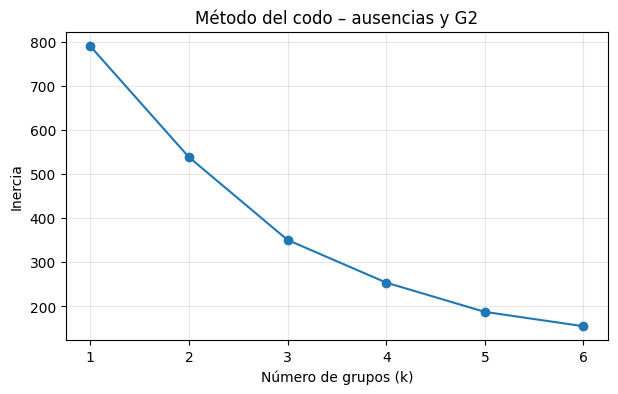

Comparación complementaria con Silhouette:


,k,silhouette
0,4,0.417
1,3,0.400
2,5,0.399
3,6,0.373
4,2,0.347


Número de grupos elegido inicialmente por Silhouette: 4
Revisa también la curva del codo; si sugiere otro k, justifica y cambia k_elegido.
Perfil descriptivo de los segmentos K-means:


,estudiantes,promedio_ausencias,promedio_G2,promedio_G3,promedio_tiempo_estudio,promedio_reprobaciones,porcentaje_bajo_rendimiento
cluster,,,,,,,
0,171,2.95,13.80,13.91,2.12,0.08,0.58
1,82,14.28,9.82,9.96,1.90,0.50,41.46
2,137,2.31,7.43,6.36,2.01,0.55,67.15
3,5,52.60,10.00,9.40,2.00,0.40,60.00


INTERPRETACIÓN AUTOMÁTICA DE CADA SEGMENTO:
- Cluster 0: n=171; G2 promedio=13.80; G3 promedio=13.91; ausencias promedio=2.95; reprobaciones previas promedio=0.08; bajo rendimiento=0.6%. Este grupo presenta una proporción relativamente baja de bajo rendimiento.
- Cluster 1: n=82; G2 promedio=9.82; G3 promedio=9.96; ausencias promedio=14.28; reprobaciones previas promedio=0.50; bajo rendimiento=41.5%. Este grupo presenta una proporción intermedia de bajo rendimiento.
- Cluster 2: n=137; G2 promedio=7.43; G3 promedio=6.36; ausencias promedio=2.31; reprobaciones previas promedio=0.55; bajo rendimiento=67.2%. Este grupo concentra una proporción alta de bajo rendimiento.
- Cluster 3: n=5; G2 promedio=10.00; G3 promedio=9.40; ausencias promedio=52.60; reprobaciones previas promedio=0.40; bajo rendimiento=60.0%. Este grupo concentra una proporción alta de bajo rendimiento.

RESUMEN DE LOS EXTREMOS:
- Mayor proporción de bajo rendimiento: cluster 2 (67.2%).
- Menor proporción de bajo rendimien

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# La guía de Unidad 5 pide elegir dos variables numéricas relevantes.
columnas_segmentacion = ["absences_mat", "G2_mat"]
X_segmentacion = datos[columnas_segmentacion].copy()

if X_segmentacion.isnull().any().any():
    raise ValueError("Hay valores nulos en las variables de segmentación. Revísalos antes de continuar.")

escalador_segmentacion = StandardScaler()
X_segmentacion_escalado = escalador_segmentacion.fit_transform(X_segmentacion)

# 1. Método del codo: calcular inercia para k entre 1 y 6.
resultados_codo = []
for k in range(1, 7):
    modelo_k = KMeans(n_clusters=k, random_state=42, n_init=10)
    modelo_k.fit(X_segmentacion_escalado)
    resultados_codo.append({"k": k, "inercia": modelo_k.inertia_})

tabla_codo = pd.DataFrame(resultados_codo)
print("Método del codo: buscar dónde la inercia deja de disminuir fuertemente.")
display(tabla_codo.round(3))

plt.figure(figsize=(7, 4))
plt.plot(tabla_codo["k"], tabla_codo["inercia"], marker="o")
plt.xlabel("Número de grupos (k)")
plt.ylabel("Inercia")
plt.title("Método del codo – ausencias y G2")
plt.xticks(range(1, 7))
plt.grid(alpha=0.3)
plt.show()

# 2. Silhouette como criterio complementario para k entre 2 y 6.
resultados_silhouette = []
for k in range(2, 7):
    modelo_k = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas_k = modelo_k.fit_predict(X_segmentacion_escalado)
    resultados_silhouette.append({
        "k": k,
        "silhouette": silhouette_score(X_segmentacion_escalado, etiquetas_k)
    })

comparacion_k = pd.DataFrame(resultados_silhouette).sort_values(
    "silhouette", ascending=False
).reset_index(drop=True)
print("Comparación complementaria con Silhouette:")
display(comparacion_k.round(3))

# Selección reproducible inicial: mayor Silhouette; contrastar visualmente con el codo.
k_elegido = int(comparacion_k.loc[0, "k"])
print("Número de grupos elegido inicialmente por Silhouette:", k_elegido)
print("Revisa también la curva del codo; si sugiere otro k, justifica y cambia k_elegido.")

modelo_segmentacion = KMeans(
    n_clusters=k_elegido, random_state=42, n_init=10
)
clusters = modelo_segmentacion.fit_predict(X_segmentacion_escalado)

resultado_segmentacion = datos.copy()
resultado_segmentacion["cluster"] = clusters
resultado_segmentacion["bajo_rendimiento"] = y.values

# G3 se usa solo para describir los grupos después de haberlos formado.
resumen_clusters = resultado_segmentacion.groupby("cluster").agg(
    estudiantes=("G3_mat", "size"),
    promedio_ausencias=("absences_mat", "mean"),
    promedio_G2=("G2_mat", "mean"),
    promedio_G3=("G3_mat", "mean"),
    promedio_tiempo_estudio=("studytime_mat", "mean"),
    promedio_reprobaciones=("failures_mat", "mean"),
    porcentaje_bajo_rendimiento=("bajo_rendimiento", lambda s: s.mean() * 100)
).round(2)

print("Perfil descriptivo de los segmentos K-means:")
display(resumen_clusters)

# Interpretaciones generadas para cada cluster con los resultados de esta ejecución.
cluster_mayor_riesgo = resumen_clusters["porcentaje_bajo_rendimiento"].idxmax()
cluster_menor_riesgo = resumen_clusters["porcentaje_bajo_rendimiento"].idxmin()
cluster_mas_ausencias = resumen_clusters["promedio_ausencias"].idxmax()
cluster_g3_mas_alto = resumen_clusters["promedio_G3"].idxmax()

print("INTERPRETACIÓN AUTOMÁTICA DE CADA SEGMENTO:")
for cluster_id, fila in resumen_clusters.iterrows():
    porcentaje = fila["porcentaje_bajo_rendimiento"]
    if porcentaje >= 50:
        lectura_riesgo = "concentra una proporción alta de bajo rendimiento"
    elif porcentaje >= 25:
        lectura_riesgo = "presenta una proporción intermedia de bajo rendimiento"
    else:
        lectura_riesgo = "presenta una proporción relativamente baja de bajo rendimiento"
    print(
        f"- Cluster {cluster_id}: n={int(fila['estudiantes'])}; "
        f"G2 promedio={fila['promedio_G2']:.2f}; G3 promedio={fila['promedio_G3']:.2f}; "
        f"ausencias promedio={fila['promedio_ausencias']:.2f}; "
        f"reprobaciones previas promedio={fila['promedio_reprobaciones']:.2f}; "
        f"bajo rendimiento={porcentaje:.1f}%. Este grupo {lectura_riesgo}."
    )
print("\nRESUMEN DE LOS EXTREMOS:")
print(f"- Mayor proporción de bajo rendimiento: cluster {cluster_mayor_riesgo} ({resumen_clusters.loc[cluster_mayor_riesgo, 'porcentaje_bajo_rendimiento']:.1f}%).")
print(f"- Menor proporción de bajo rendimiento: cluster {cluster_menor_riesgo} ({resumen_clusters.loc[cluster_menor_riesgo, 'porcentaje_bajo_rendimiento']:.1f}%).")
print(f"- Mayor promedio de ausencias: cluster {cluster_mas_ausencias} ({resumen_clusters.loc[cluster_mas_ausencias, 'promedio_ausencias']:.2f}).")
print(f"- Mayor promedio de calificación final G3: cluster {cluster_g3_mas_alto} ({resumen_clusters.loc[cluster_g3_mas_alto, 'promedio_G3']:.2f}/20).")
print("Los números de cluster son etiquetas técnicas, no un orden de rendimiento.")


### Interpretación descriptiva de los segmentos

La celda anterior imprime los perfiles calculados en esta ejecución y genera cuatro observaciones automáticas: grupo con mayor proporción de bajo rendimiento, menor proporción, mayor promedio de ausencias y mayor G3 promedio.

Al redactar la interpretación final:

- Describe cada cluster usando sus promedios y su tamaño en `resumen_clusters`.
- No reutilices números de ejecuciones anteriores: los identificadores y perfiles pueden cambiar al modificar las variables o el número de grupos.
- Recuerda que `G3_mat` se usa solo para describir los grupos después de formarlos, no para entrenar K-means.
- Los segmentos son exploratorios y no demuestran causalidad ni constituyen un diagnóstico de estudiantes.

**Conclusión metodológica:** la cantidad de grupos se selecciona inicialmente con Silhouette y se contrasta con el método del codo. Si ambos criterios no coinciden claramente, se reporta esa limitación y la elección como preliminar.


### Comparación con clustering jerárquico

La guía de Unidad 5 pide aplicar clustering jerárquico sobre la misma matriz estandarizada de dos variables (`X_segmentacion_escalado`) y comparar las etiquetas con las de K-means mediante una tabla cruzada. Se utiliza el mismo número de grupos (`k_elegido`) y el método `ward`.


In [11]:
from sklearn.cluster import AgglomerativeClustering

modelo_jerarquico = AgglomerativeClustering(
    n_clusters=k_elegido,
    linkage="ward"
)

etiquetas_jerarquicas = modelo_jerarquico.fit_predict(X_segmentacion_escalado)
resultado_segmentacion["cluster_jerarquico"] = etiquetas_jerarquicas

tabla_cruzada_clusters = pd.crosstab(
    resultado_segmentacion["cluster"],
    resultado_segmentacion["cluster_jerarquico"],
    rownames=["K-means"],
    colnames=["Jerárquico"]
)

print("Comparación de asignaciones: K-means frente a clustering jerárquico")
display(tabla_cruzada_clusters)

print("Cantidad de estudiantes por grupo jerárquico:")
display(resultado_segmentacion["cluster_jerarquico"].value_counts().sort_index())

print("La tabla cruzada compara coincidencias de asignación; los números de cluster de cada técnica no tienen un significado ordinal.")


Comparación de asignaciones: K-means frente a clustering jerárquico


Jerárquico,0,1,2,3
K-means,,,,
0,46,125,0,0
1,0,20,62,0
2,132,0,5,0
3,0,0,0,5


Cantidad de estudiantes por grupo jerárquico:


,count
cluster_jerarquico,
0,178
1,145
2,67
3,5


La tabla cruzada compara coincidencias de asignación; los números de cluster de cada técnica no tienen un significado ordinal.


### Segmentación con DBSCAN

DBSCAN agrupa observaciones por densidad y puede marcar registros aislados con la etiqueta `-1` (ruido u observaciones atípicas). Se aplica sobre la misma matriz estandarizada de dos variables que K-means y el clustering jerárquico. Se prueban varios valores de `eps` con `min_samples=5`.

Se revisa cuántos grupos encuentra y qué proporción deja como ruido. Si no aparece una configuración interpretable, se documenta esa limitación en lugar de forzar una conclusión.


In [12]:
from sklearn.cluster import DBSCAN

# Valores candidatos de eps para la matriz estandarizada de dos variables.
eps_candidatos = [0.3, 0.5, 0.7, 0.9, 1.1, 1.3, 1.5, 1.8, 2.0, 2.5]
min_samples_dbscan = 5
resultados_dbscan = []
modelos_dbscan = {}

for eps in eps_candidatos:
    modelo_db = DBSCAN(eps=eps, min_samples=min_samples_dbscan)
    etiquetas = modelo_db.fit_predict(X_segmentacion_escalado)
    modelos_dbscan[eps] = etiquetas

    grupos = set(etiquetas) - {-1}
    cantidad_grupos = len(grupos)
    cantidad_ruido = int((etiquetas == -1).sum())
    porcentaje_ruido = cantidad_ruido / len(etiquetas) * 100

    mascara_no_ruido = etiquetas != -1
    etiquetas_sin_ruido = etiquetas[mascara_no_ruido]
    silhouette_db = np.nan
    if (cantidad_grupos >= 2 and
        2 <= len(set(etiquetas_sin_ruido)) < len(etiquetas_sin_ruido)):
        silhouette_db = silhouette_score(
            X_segmentacion_escalado[mascara_no_ruido],
            etiquetas_sin_ruido
        )

    resultados_dbscan.append({
        "eps": eps,
        "cantidad_grupos": cantidad_grupos,
        "registros_ruido": cantidad_ruido,
        "porcentaje_ruido": porcentaje_ruido,
        "silhouette_sin_ruido": silhouette_db
    })

tabla_dbscan = pd.DataFrame(resultados_dbscan)
print("Comparación de parámetros DBSCAN (-1 representa ruido):")
display(tabla_dbscan.round(3))

# Criterio exploratorio: al menos dos grupos, Silhouette calculable y hasta 50% de ruido.
# El 50% es una referencia práctica de esta exploración, no una regla universal.
soluciones_validas = tabla_dbscan[
    (tabla_dbscan["cantidad_grupos"] >= 2) &
    (tabla_dbscan["porcentaje_ruido"] <= 50) &
    (tabla_dbscan["silhouette_sin_ruido"].notna())
]

if not soluciones_validas.empty:
    fila_elegida = soluciones_validas.sort_values(
        "silhouette_sin_ruido", ascending=False
    ).iloc[0]
    eps_elegido = float(fila_elegida["eps"])
    etiquetas_dbscan = modelos_dbscan[eps_elegido]
    resultado_segmentacion["cluster_dbscan"] = etiquetas_dbscan

    print(f"Valor eps seleccionado de forma preliminar: {eps_elegido}")
    print("Grupos DBSCAN (sin contar -1):", len(set(etiquetas_dbscan) - {-1}))
    print("Distribución de etiquetas DBSCAN (-1 = ruido):")
    display(pd.Series(etiquetas_dbscan, name="cluster_dbscan").value_counts().sort_index())
else:
    eps_elegido = None
    print(
        "Ningún eps probado produjo una solución con al menos dos grupos, "
        "Silhouette calculable y como máximo 50% de ruido. DBSCAN no se considera "
        "una segmentación interpretable con esta configuración; se documenta como limitación."
    )


Comparación de parámetros DBSCAN (-1 representa ruido):


,eps,cantidad_grupos,registros_ruido,porcentaje_ruido,silhouette_sin_ruido
0,0.3,4,27,6.835,0.165
1,0.5,2,14,3.544,0.548
2,0.7,2,9,2.278,0.541
3,0.9,2,7,1.772,0.537
4,1.1,1,4,1.013,NaN
5,1.3,1,4,1.013,NaN
6,1.5,1,3,0.759,NaN
7,1.8,1,2,0.506,NaN
8,2.0,1,2,0.506,NaN
9,2.5,1,0,0.000,NaN


Valor eps seleccionado de forma preliminar: 0.5
Grupos DBSCAN (sin contar -1): 2
Distribución de etiquetas DBSCAN (-1 = ruido):


,count
cluster_dbscan,
-1,14
0,368
1,13





- **K-means:** permite definir una cantidad de grupos y describir perfiles usando las dos variables seleccionadas. Se utiliza como técnica principal de segmentación exploratoria.
- **Clustering jerárquico:** aplica el mismo criterio de distancia y permite comparar las asignaciones con K-means mediante la tabla cruzada. Es útil para comprobar si aparece una estructura parecida.
- **DBSCAN:** busca grupos por densidad y puede identificar puntos aislados como ruido (`-1`). Su utilidad depende de `eps`; si los resultados muestran un solo grupo o mucho ruido, se reporta que no produjo una segmentación clara.




### Resultados de la comparación de técnicas

Con el archivo `student-mat(4).csv` (395 registros), la ejecución de prueba produjo los siguientes resultados:

- **K-means:** el Silhouette más alto entre los valores evaluados fue para `k=4` (`0.417`). La curva de inercia disminuye de 790.000 (`k=1`) a 253.925 (`k=4`) y luego sigue bajando con menor cambio relativo; por eso `k=4` se selecciona como opción preliminar apoyada en Silhouette, no como una cantidad indiscutible.
- **Perfil de K-means:** el grupo 0 contiene 171 estudiantes (G3 promedio 13.91; 0.58% de bajo rendimiento); el grupo 1, 82 estudiantes (G3 9.96; 41.46% de bajo rendimiento); el grupo 2, 137 estudiantes (G3 6.36; 67.15% de bajo rendimiento); y el grupo 3, 5 estudiantes (52.60 ausencias promedio; 60% de bajo rendimiento). El grupo 3 es muy pequeño y debe interpretarse con cautela: representa un perfil extremo de ausencias, no un segmento generalizable por sí solo.
- **Jerárquico:** la tabla cruzada muestra coincidencias parciales con K-means, pero no una correspondencia exacta de etiquetas. Los números de cluster son etiquetas arbitrarias; se comparan los tamaños y perfiles, no el número del cluster como si tuviera orden.
- **DBSCAN:** con `eps=0.5` y `min_samples=5` se obtuvieron 2 grupos y 14 registros marcados como ruido (3.5%). El Silhouette de 0.548 se calculó solo sobre los puntos no marcados como ruido, por lo que no debe compararse directamente con el Silhouette de K-means como si se hubiera calculado sobre el mismo conjunto de observaciones.




##  Modelo predictivo y evaluación


### Definición del objetivo y separación de datos

Se construye un modelo de clasificación para identificar estudiantes con bajo rendimiento al finalizar el periodo. El objetivo `bajo_rendimiento` vale 1 cuando `G3_mat < 10` y 0 cuando `G3_mat >= 10`.

Se utiliza `X` como matriz de predictores y `y` como variable objetivo. `G3_mat` se excluye de `X` porque es la nota que se desea predecir. Los predictores `G1_mat`, `G2_mat` y `grade_progress_mat` solo son válidos si la alerta se genera después de conocer la segunda evaluación. Por ello, el alcance temporal del modelo es **después de G2 y antes de conocer G3**.


In [13]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Comprobación de fuga directa: G3 y el objetivo no pueden estar en X.
columnas_prohibidas = ["G3_mat", "bajo_rendimiento"]
columnas_prohibidas_presentes = [c for c in columnas_prohibidas if c in X.columns]
print("Columnas de resultado que aparecen en X:", columnas_prohibidas_presentes)
assert not columnas_prohibidas_presentes, "Hay fuga directa: elimina la variable objetivo de X."

# Dividir 70% para entrenamiento y 30% para prueba, conservando la proporción de clases.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
print("Tamaño de entrenamiento:", X_train.shape)
print("Tamaño de prueba:", X_test.shape)

# Primer modelo: árbol de decisión con profundidad máxima 4.
modelo_arbol = DecisionTreeClassifier(max_depth=4, random_state=42)
modelo_arbol.fit(X_train, y_train)

pred_train = modelo_arbol.predict(X_train)
pred_test = modelo_arbol.predict(X_test)
accuracy_train = accuracy_score(y_train, pred_train)
accuracy_test = accuracy_score(y_test, pred_test)

print("Accuracy de entrenamiento:", round(accuracy_train, 3))
print("Accuracy de prueba:", round(accuracy_test, 3))

# Matriz de confusión: filas = valor real; columnas = predicción.
matriz = confusion_matrix(y_test, pred_test, labels=[0, 1])
print("Matriz de confusión (filas = real; columnas = predicción):")
display(pd.DataFrame(
    matriz,
    index=["Real: aprobación", "Real: bajo rendimiento"],
    columns=["Predicho: aprobación", "Predicho: bajo rendimiento"]
))

# Métricas para la clase positiva 1 = bajo rendimiento.
precision = precision_score(y_test, pred_test, pos_label=1, zero_division=0)
recall = recall_score(y_test, pred_test, pos_label=1, zero_division=0)
f1 = f1_score(y_test, pred_test, pos_label=1, zero_division=0)
print("Precisión para bajo rendimiento:", round(precision, 3))
print("Exhaustividad (recall) para bajo rendimiento:", round(recall, 3))
print("F1 para bajo rendimiento:", round(f1, 3))

# Comparación con una referencia que predice siempre la clase mayoritaria.
clase_mayoritaria = int(y_train.mode().iloc[0])
pred_baseline = np.full(len(y_test), clase_mayoritaria)
accuracy_baseline = accuracy_score(y_test, pred_baseline)
print("Accuracy de referencia (clase mayoritaria):", round(accuracy_baseline, 3))

# Importancia relativa de las variables utilizadas por el árbol.
importancias = pd.Series(
    modelo_arbol.feature_importances_, index=X.columns
).sort_values(ascending=False)
print("15 variables más importantes según el árbol:")
display(importancias.head(15).to_frame("importancia"))


Columnas de resultado que aparecen en X: []
Tamaño de entrenamiento: (276, 64)
Tamaño de prueba: (119, 64)
Accuracy de entrenamiento: 0.953
Accuracy de prueba: 0.866
Matriz de confusión (filas = real; columnas = predicción):


,Predicho: aprobación,Predicho: bajo rendimiento
Real: aprobación,72,8
Real: bajo rendimiento,8,31


Precisión para bajo rendimiento: 0.795
Exhaustividad (recall) para bajo rendimiento: 0.795
F1 para bajo rendimiento: 0.795
Accuracy de referencia (clase mayoritaria): 0.672
15 variables más importantes según el árbol:


,importancia
G2_mat,0.861751
reason_mat_course,0.035425
age_mat,0.032795
freetime_mat,0.027996
Fjob_mat_other,0.024417
G1_mat,0.010290
reason_mat_reputation,0.007326
traveltime_mat,0.000000
famrel_mat,0.000000
failures_mat,0.000000


### Revisión de fuga de datos y sobreajuste

La comprobación automática de la celda anterior debe mostrar una lista vacía y `G3_mat` debe estar ausente de `X`. La variable `grade_progress_mat` se calcula con `G1_mat` y `G2_mat`, no con `G3_mat`; solo es válida para una alerta generada después de conocer G2.

El sobreajuste se revisa comparando el accuracy de entrenamiento con el de prueba. Una diferencia grande puede indicar que el árbol memorizó casos del entrenamiento. La conclusión debe considerar también matriz de confusión, precisión, recall y F1; no basta con accuracy.


In [14]:
brecha_accuracy = accuracy_train - accuracy_test
print("Diferencia entre accuracy de entrenamiento y prueba:", round(brecha_accuracy, 3))

if brecha_accuracy > 0.10:
    print("Advertencia: la brecha es amplia y puede indicar sobreajuste. Revisa la complejidad del árbol.")
else:
    print("No se observa una brecha superior a 0.10 en esta ejecución; revisa igualmente todas las métricas.")

# Interpretación cuantitativa de los errores para la clase positiva (bajo rendimiento).
verdaderos_negativos, falsos_positivos, falsos_negativos, verdaderos_positivos = matriz.ravel()
print(f"Estudiantes con bajo rendimiento detectados correctamente (TP): {verdaderos_positivos}")
print(f"Estudiantes con bajo rendimiento no detectados (FN): {falsos_negativos}")
print(f"Falsas alarmas (FP): {falsos_positivos}")
print(f"Aprobados identificados correctamente (TN): {verdaderos_negativos}")


Diferencia entre accuracy de entrenamiento y prueba: 0.087
No se observa una brecha superior a 0.10 en esta ejecución; revisa igualmente todas las métricas.
Estudiantes con bajo rendimiento detectados correctamente (TP): 31
Estudiantes con bajo rendimiento no detectados (FN): 8
Falsas alarmas (FP): 8
Aprobados identificados correctamente (TN): 72


### comparar distintas profundidades del árbol

Se elige la opción 2 de la guía: probar profundidades 2, 4, 8 y sin límite (`None`), comparando accuracy de entrenamiento y prueba. Si la precisión de entrenamiento aumenta mucho y la de prueba se estanca o disminuye, puede ser señal de sobreajuste.

In [15]:
resultados_profundidad = []

for profundidad in [2, 4, 8, None]:
    arbol = DecisionTreeClassifier(max_depth=profundidad, random_state=42)
    arbol.fit(X_train, y_train)
    pred_train_profundidad = arbol.predict(X_train)
    pred_test_profundidad = arbol.predict(X_test)

    acc_train = accuracy_score(y_train, pred_train_profundidad)
    acc_test = accuracy_score(y_test, pred_test_profundidad)
    resultados_profundidad.append({
        "max_depth": "Sin límite" if profundidad is None else profundidad,
        "accuracy_entrenamiento": acc_train,
        "accuracy_prueba": acc_test,
        "brecha": acc_train - acc_test
    })

tabla_profundidades = pd.DataFrame(resultados_profundidad)
print("Comparación de profundidades del árbol:")
display(tabla_profundidades.round(3))

# Elegir como referencia la profundidad con mayor accuracy de prueba;
# en empates, preferir menor brecha entre entrenamiento y prueba.
mejor_profundidad = tabla_profundidades.sort_values(
    ["accuracy_prueba", "brecha"], ascending=[False, True]
).iloc[0]
print(
    "Profundidad con mejor resultado de prueba según este criterio:",
    mejor_profundidad["max_depth"]
)


Comparación de profundidades del árbol:


,max_depth,accuracy_entrenamiento,accuracy_prueba,brecha
0,2,0.924,0.908,0.016
1,4,0.953,0.866,0.087
2,8,1.000,0.857,0.143
3,Sin límite,1.000,0.857,0.143


Profundidad con mejor resultado de prueba según este criterio: 2


### Interpretación del modelo predictivo

La siguiente celda genera una guía con los resultados calculados en la partición de prueba. Utiliza esos valores para explicar si el árbol detecta estudiantes con bajo rendimiento, qué errores comete y si supera al modelo de referencia.

Recuerda: precision indica qué proporción de las alertas emitidas era correcta; recall indica qué proporción de todos los casos reales de bajo rendimiento detectó; F1 resume el equilibrio entre ambas. Una métrica baja no invalida el ejercicio si se interpreta con honestidad y se documentan sus limitaciones.


In [16]:
# Resumen automático para redactar la interpretación del modelo
print("INTERPRETACIÓN DE LA EVALUACIÓN DEL ÁRBOL")
print(f"1. Accuracy de prueba: {accuracy_test:.3f}; accuracy de referencia: {accuracy_baseline:.3f}.")
if accuracy_test > accuracy_baseline:
    print("   El modelo supera la referencia simple en accuracy.")
elif accuracy_test == accuracy_baseline:
    print("   El modelo iguala la referencia simple en accuracy.")
else:
    print("   El modelo no supera la referencia simple en accuracy.")
print(f"2. Precision (bajo rendimiento): {precision:.3f}.")
print(f"3. Recall (bajo rendimiento): {recall:.3f}.")
print(f"4. F1 (bajo rendimiento): {f1:.3f}.")
print(f"5. Diferencia de accuracy entrenamiento-prueba: {brecha_accuracy:.3f}.")
print(f"6. Errores: {falsos_negativos} falsos negativos y {falsos_positivos} falsos positivos.")
print("7. La profundidad de referencia se muestra en la tabla de comparación; confirma el equilibrio entre accuracy de prueba y brecha.")
print("Uso: el modelo puede apoyar la priorización de seguimiento, nunca sustituir la revisión docente.")


INTERPRETACIÓN DE LA EVALUACIÓN DEL ÁRBOL
1. Accuracy de prueba: 0.866; accuracy de referencia: 0.672.
   El modelo supera la referencia simple en accuracy.
2. Precision (bajo rendimiento): 0.795.
3. Recall (bajo rendimiento): 0.795.
4. F1 (bajo rendimiento): 0.795.
5. Diferencia de accuracy entrenamiento-prueba: 0.087.
6. Errores: 8 falsos negativos y 8 falsos positivos.
7. La profundidad de referencia se muestra en la tabla de comparación; confirma el equilibrio entre accuracy de prueba y brecha.
Uso: el modelo puede apoyar la priorización de seguimiento, nunca sustituir la revisión docente.


### Resultados de evaluación del modelo (ejecución verificada)

Con la partición estratificada de 70% para entrenamiento (276 registros) y 30% para prueba (119 registros), el árbol inicial (`max_depth=4`) obtuvo:

- Accuracy de entrenamiento: **0.953**.
- Accuracy de prueba: **0.866**.
- Accuracy de referencia por clase mayoritaria: **0.672**.
- Precisión para bajo rendimiento: **0.795**.
- Recall para bajo rendimiento: **0.795**.
- F1 para bajo rendimiento: **0.795**.
- Matriz de confusión: 72 verdaderos negativos, 8 falsos positivos, 8 falsos negativos y 31 verdaderos positivos.

El árbol supera la referencia simple en accuracy. La diferencia entre accuracy de entrenamiento y prueba es **0.087**, lo que no supera el umbral orientativo de 0.10 utilizado en este notebook, aunque sí existe una brecha que conviene vigilar. El modelo dejó sin detectar 8 estudiantes que sí pertenecían a la clase de bajo rendimiento y generó 8 falsas alarmas.

En la comparación de profundidades, `max_depth=2` obtuvo accuracy de prueba **0.908** y una brecha de **0.016**; `max_depth=4`, 0.866 y 0.087; `max_depth=8` y sin límite, 0.857 y 0.143. En esta partición, el árbol menos profundo mostró mejor equilibrio y las versiones más complejas dieron señales de sobreajuste. Como las profundidades se compararon con la misma partición de prueba, el resultado es exploratorio y sería conveniente confirmarlo con validación cruzada.

La variable G2 tuvo la mayor importancia en el árbol (`0.862`). Esto es coherente con el alcance planteado: el modelo pretende emitir una alerta **después de conocer G2 y antes de conocer G3**. No es una predicción que pueda hacerse al inicio del periodo.



##  Detección de anomalías y experimentación

### Ruta seleccionada: detección de anomalías con Isolation Forest

Se selecciona la **Ruta 1: detección de anomalías**, recomendada en la ficha de la Unidad 7 porque puede aplicarse a datos numéricos y no requiere una columna de texto libre ni una estructura de transacciones.

El objetivo es identificar estudiantes cuyos valores combinados de ausencias y calificaciones de las dos primeras evaluaciones se aparten del patrón general. Una anomalía es una observación inusual, no necesariamente un error ni una evidencia de bajo rendimiento.

**Variables seleccionadas:** `absences_mat`, `G1_mat` y `G2_mat`. Se excluye `G3_mat` porque representa la calificación final. Se mantienen tres variables numéricas relevantes para el seguimiento académico.

**Parámetros del experimento:** `n_estimators=200`, `random_state=42` y tres escenarios de `contamination`: 0.05, 0.10 y 0.15. `contamination` es una proporción esperada usada para fijar el umbral del algoritmo; no demuestra que esa proporción sea realmente anómala.

No se eligen las rutas de minería de texto o MLflow: el dataset no contiene una columna de texto libre pertinente y el objetivo de esta actividad se cubre con un experimento de detección de anomalías comparando configuraciones.


In [17]:
from sklearn.ensemble import IsolationForest

# Variables numéricas seleccionadas para el experimento.
columnas_anomalias = [
    "absences_mat",
    "G1_mat",
    "G2_mat"
]

# Validaciones para evitar ejecutar el experimento con columnas ausentes o no numéricas.
columnas_faltantes = [c for c in columnas_anomalias if c not in datos.columns]
if columnas_faltantes:
    raise KeyError(f"Faltan columnas para Isolation Forest: {columnas_faltantes}")

X_anomalias = datos[columnas_anomalias].copy()
if X_anomalias.isnull().any().any():
    raise ValueError("Hay valores nulos en las variables de anomalías. Revísalos antes de continuar.")
if not all(pd.api.types.is_numeric_dtype(X_anomalias[c]) for c in columnas_anomalias):
    raise TypeError("Todas las variables seleccionadas para Isolation Forest deben ser numéricas.")

print("Variables utilizadas:", columnas_anomalias)
print("Dimensiones de la matriz:", X_anomalias.shape)
display(X_anomalias.describe().round(2))

Variables utilizadas: ['absences_mat', 'G1_mat', 'G2_mat']
Dimensiones de la matriz: (395, 3)


,absences_mat,G1_mat,G2_mat
count,395.00,395.00,395.00
mean,5.71,10.91,10.71
std,8.00,3.32,3.76
min,0.00,3.00,0.00
25%,0.00,8.00,9.00
50%,4.00,11.00,11.00
75%,8.00,13.00,13.00
max,75.00,19.00,19.00


### Comparación de tres configuraciones

La guía pide comparar al menos dos o tres configuraciones. Se mantiene la misma matriz de variables y la misma semilla aleatoria para que la comparación sea reproducible; solo cambia `contamination`.

Isolation Forest no exige escalado por distancia como K-means. Se utilizan los valores numéricos originales y se documenta esta decisión para evitar transformar innecesariamente las variables.

In [18]:
configuraciones_contamination = [0.05, 0.10, 0.15]
resultados_iforest = []
predicciones_iforest = {}
modelos_iforest = {}

for contamination in configuraciones_contamination:
    modelo_if = IsolationForest(
        n_estimators=200,
        contamination=contamination,
        random_state=42
    )
    etiquetas = modelo_if.fit_predict(X_anomalias)
    # IsolationForest devuelve -1 para anomalía y 1 para observación normal.
    predicciones_iforest[contamination] = etiquetas
    modelos_iforest[contamination] = modelo_if

    cantidad_anomalias = int((etiquetas == -1).sum())
    porcentaje_observado = cantidad_anomalias / len(X_anomalias) * 100

    resultados_iforest.append({
        "contamination_configurada": contamination,
        "estudiantes_evaluados": len(X_anomalias),
        "anomalias_detectadas": cantidad_anomalias,
        "porcentaje_detectado": porcentaje_observado
    })

comparacion_iforest = pd.DataFrame(resultados_iforest)
print("Comparación de ejecuciones de Isolation Forest:")
display(comparacion_iforest.round(2))

# Elegimos 10% como escenario intermedio para examinar casos concretos.
contamination_referencia = 0.10
etiquetas_referencia = predicciones_iforest[contamination_referencia]
modelo_referencia = modelos_iforest[contamination_referencia]

datos_anomalias = datos.copy()
datos_anomalias["etiqueta_iforest_10"] = etiquetas_referencia
datos_anomalias["es_anomalia_iforest_10"] = datos_anomalias["etiqueta_iforest_10"].eq(-1)
datos_anomalias["score_iforest_10"] = modelo_referencia.score_samples(X_anomalias)

display(datos_anomalias["es_anomalia_iforest_10"].value_counts().rename(index={True: "Anomalía", False: "Normal"}).to_frame("cantidad"))

Comparación de ejecuciones de Isolation Forest:


,contamination_configurada,estudiantes_evaluados,anomalias_detectadas,porcentaje_detectado
0,0.05,395,20,5.06
1,0.10,395,39,9.87
2,0.15,395,60,15.19


,cantidad
es_anomalia_iforest_10,
Normal,356
Anomalía,39


### Perfil de las observaciones marcadas y visualización

Se toma el escenario intermedio (`contamination=0.10`) como referencia para examinar los registros. Esta elección facilita la inspección, pero no significa que 10% sea la proporción verdadera de anomalías.

Los registros marcados se conservan en la base; el algoritmo no autoriza eliminarlos automáticamente. El puntaje `score_iforest_10` es más bajo para los casos que el modelo considera más aislados.

Perfil descriptivo con contamination=0.10:


,estudiantes,promedio_ausencias,mediana_ausencias,promedio_G1,promedio_G2
grupo_iforest,,,,,
Anomalía,39,13.77,6.0,11.44,9.54
Normal,356,4.83,4.0,10.85,10.84


Primeros casos marcados (puntaje más bajo = más aislado):


,absences_mat,G1_mat,G2_mat,score_iforest_10
276,75,10,9,-0.723136
74,54,11,12,-0.691895
183,56,9,9,-0.672034
198,24,18,18,-0.670013
137,0,4,0,-0.664557
47,4,19,19,-0.659664
260,21,17,18,-0.646868
315,40,13,11,-0.644899
130,0,12,0,-0.639474
374,0,19,18,-0.631327


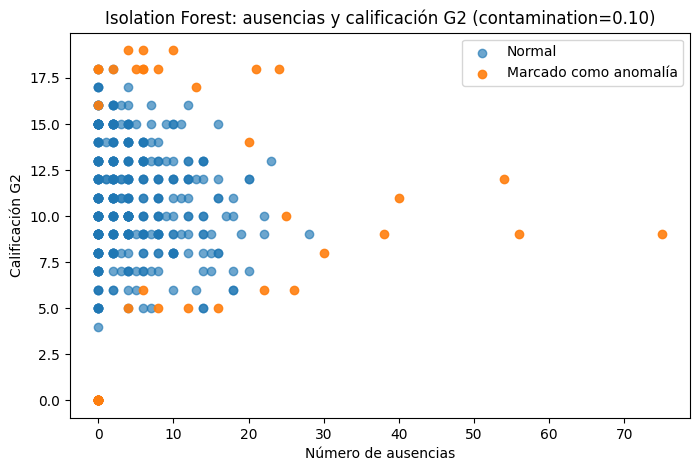

In [19]:
# Resumen comparativo entre el grupo marcado como anomalía y el grupo normal.
resumen_iforest = (
    datos_anomalias
    .assign(grupo_iforest=lambda d: np.where(d["es_anomalia_iforest_10"], "Anomalía", "Normal"))
    .groupby("grupo_iforest")
    .agg(
        estudiantes=("G2_mat", "size"),
        promedio_ausencias=("absences_mat", "mean"),
        mediana_ausencias=("absences_mat", "median"),
        promedio_G1=("G1_mat", "mean"),
        promedio_G2=("G2_mat", "mean")
    )
    .round(2)
)
print("Perfil descriptivo con contamination=0.10:")
display(resumen_iforest)

# Mostrar hasta 15 registros más aislados para revisión humana.
casos_marcados = (
    datos_anomalias.loc[
        datos_anomalias["es_anomalia_iforest_10"],
        columnas_anomalias + ["score_iforest_10"]
    ]
    .sort_values("score_iforest_10", ascending=True)
)
print("Primeros casos marcados (puntaje más bajo = más aislado):")
display(casos_marcados.head(15))

# Gráfico de dos variables; el modelo se ajustó con las tres variables seleccionadas.
plt.figure(figsize=(8, 5))
mascara_anomalia = datos_anomalias["es_anomalia_iforest_10"]
plt.scatter(
    datos_anomalias.loc[~mascara_anomalia, "absences_mat"],
    datos_anomalias.loc[~mascara_anomalia, "G2_mat"],
    label="Normal",
    alpha=0.65
)
plt.scatter(
    datos_anomalias.loc[mascara_anomalia, "absences_mat"],
    datos_anomalias.loc[mascara_anomalia, "G2_mat"],
    label="Marcado como anomalía",
    alpha=0.9
)
plt.title("Isolation Forest: ausencias y calificación G2 (contamination=0.10)")
plt.xlabel("Número de ausencias")
plt.ylabel("Calificación G2")
plt.legend()
plt.show()

### Interpretación del experimento

La siguiente celda genera los conteos y porcentajes reales de las tres configuraciones de Isolation Forest y compara el perfil promedio de las observaciones marcadas con el grupo normal.

Interpreta los resultados sin asumir que una observación marcada sea un error: `contamination` modifica el umbral del modelo. Los casos señalados deben revisarse individualmente antes de cualquier decisión académica.


In [20]:
# Interpretación automática a partir de las ejecuciones de Isolation Forest
print("INTERPRETACIÓN DE LAS CONFIGURACIONES")
for _, fila in comparacion_iforest.sort_values("contamination_configurada").iterrows():
    print(
        f"- contamination={fila['contamination_configurada']:.0%}: "
        f"{int(fila['anomalias_detectadas'])} de {int(fila['estudiantes_evaluados'])} estudiantes "
        f"marcados ({fila['porcentaje_detectado']:.1f}%)."
    )

print("\nCOMPARACIÓN DE PERFILES (contamination=10%)")
if {"Anomalía", "Normal"}.issubset(set(resumen_iforest.index)):
    for variable, etiqueta in [
        ("promedio_ausencias", "ausencias promedio"),
        ("promedio_G1", "G1 promedio"),
        ("promedio_G2", "G2 promedio")
    ]:
        valor_anomalia = resumen_iforest.loc["Anomalía", variable]
        valor_normal = resumen_iforest.loc["Normal", variable]
        print(f"- {etiqueta}: anomalías={valor_anomalia:.2f}; normales={valor_normal:.2f}.")
else:
    print("No fue posible comparar ambos grupos en esta ejecución.")

print("\nLectura: las diferencias describen el comportamiento de los grupos marcados; no prueban error, causalidad ni bajo rendimiento.")


INTERPRETACIÓN DE LAS CONFIGURACIONES
- contamination=5%: 20 de 395 estudiantes marcados (5.1%).
- contamination=10%: 39 de 395 estudiantes marcados (9.9%).
- contamination=15%: 60 de 395 estudiantes marcados (15.2%).

COMPARACIÓN DE PERFILES (contamination=10%)
- ausencias promedio: anomalías=13.77; normales=4.83.
- G1 promedio: anomalías=11.44; normales=10.85.
- G2 promedio: anomalías=9.54; normales=10.84.

Lectura: las diferencias describen el comportamiento de los grupos marcados; no prueban error, causalidad ni bajo rendimiento.


### Resultados de Isolation Forest (ejecución verificada)

Con 395 estudiantes y las variables `absences_mat`, `G1_mat` y `G2_mat`, los tres escenarios detectaron:

| contamination configurada | Estudiantes marcados | Porcentaje observado |
|---:|---:|---:|
| 5% | 20 | 5.1% |
| 10% | 39 | 9.9% |
| 15% | 60 | 15.2% |

Para el escenario de 10%, el grupo marcado como anomalía tuvo 39 estudiantes y el grupo normal 356. El grupo marcado presentó 13.77 ausencias promedio (mediana 6), G1 promedio 11.44 y G2 promedio 9.54. El grupo normal presentó 4.83 ausencias promedio (mediana 4), G1 promedio 10.85 y G2 promedio 10.84.

Esto muestra que el modelo marca combinaciones con ausencias promedio mayores y G2 promedio menor en este conjunto. Sin embargo, Isolation Forest no dispone de una etiqueta real de anomalía para estos estudiantes; por eso no se pueden calcular precisión, recall ni afirmar cuántos son falsos positivos o falsos negativos. Cada caso requiere revisión humana y contextual.

*Estos valores corresponden a la ejecución de verificación con el CSV adjunto. La contaminación es un parámetro del algoritmo, no una tasa real conocida de errores o anomalías.*